# FFT-Generated Dataset -> Neural Network Option Pricer

This notebook implements the fourth pricing method for the project:

1. Price a large number of synthetic European call options with the FFT
   (Carr-Madan) method, producing an `(x, y)` dataset where
   `x = (spot, strike, rate, sigma, tau)` and `y = FFT price`.
2. Train a PyTorch feedforward neural network to regress price from those
   5 input parameters.
3. Apply the trained network to brand-new, previously unseen parameter
   combinations and compare its predictions against freshly computed FFT
   (and BSM, as an exact sanity check) prices.

This mirrors the approach in `material/Machine learning for quantitative
finance fast derivative pricing hedging and fitting.pdf`: once trained, the
network replaces repeated FFT/characteristic-function evaluations with a
near-instant forward pass, which is the computational-efficiency story
explored further in `03_comparison.ipynb`.

In [1]:
from __future__ import annotations

import math
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

SEED = 20261116
np.random.seed(SEED)
torch.manual_seed(SEED)

FFT_N = 16384
FFT_ETA = 0.25
FFT_ALPHA = 1.5

DATA_DIR = Path("data")
MODELS_DIR = Path("models")
DATA_DIR.mkdir(exist_ok=True)
MODELS_DIR.mkdir(exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


## Pricing functions (BSM and Carr-Madan FFT, copied from `code.py` / `01_bsm_mc_fft.ipynb`)

In [2]:
def norm_cdf(x: float) -> float:
    return 0.5 * math.erfc(-x / math.sqrt(2.0))


def bsm_call(spot: float, strike: float, rate: float, sigma: float, tau: float) -> float:
    """European call price, continuously compounded rate, time-to-maturity tau."""
    if spot <= 0 or strike <= 0 or sigma < 0 or tau < 0:
        raise ValueError("spot and strike must be positive; sigma and tau nonnegative")
    if tau == 0:
        return max(spot - strike, 0.0)
    if sigma == 0:
        return max(spot - strike * math.exp(-rate * tau), 0.0)
    vol_time = sigma * math.sqrt(tau)
    d1 = (math.log(spot / strike) + (rate + 0.5 * sigma * sigma) * tau) / vol_time
    d2 = d1 - vol_time
    return spot * norm_cdf(d1) - strike * math.exp(-rate * tau) * norm_cdf(d2)


def carr_madan_call(spot: float, strike: float, rate: float, sigma: float,
                    tau: float, n: int = FFT_N, eta: float = FFT_ETA,
                    alpha: float = FFT_ALPHA) -> float:
    """Carr-Madan FFT inversion for a Black-Scholes European call."""
    if spot <= 0 or strike <= 0 or sigma < 0 or tau < 0:
        raise ValueError("spot and strike must be positive; sigma and tau nonnegative")
    if tau == 0 or sigma == 0:
        return bsm_call(spot, strike, rate, sigma, tau)
    if n < 16 or n & (n - 1):
        raise ValueError("FFT size n must be a power of two >= 16")
    if eta <= 0 or alpha <= 0:
        raise ValueError("eta and alpha must be positive")

    j = np.arange(n)
    u = eta * j
    log_forward = math.log(spot) + (rate - 0.5 * sigma * sigma) * tau
    z = u - 1j * (alpha + 1.0)
    phi = np.exp(1j * z * log_forward - 0.5 * sigma * sigma * tau * z * z)
    denominator = alpha * alpha + alpha - u * u + 1j * (2.0 * alpha + 1.0) * u
    psi = math.exp(-rate * tau) * phi / denominator

    weights = np.ones(n)
    weights[1::2] = 4.0
    weights[2:-1:2] = 2.0
    weights /= 3.0
    weights[0] = 1.0 / 3.0
    weights[-1] = 1.0 / 3.0
    b = math.pi / eta
    integrand = np.exp(1j * b * u) * psi * eta * weights
    fft_values = np.fft.fft(integrand)
    dk = 2.0 * math.pi / (n * eta)
    log_strike_grid = -b + dk * np.arange(n)
    calls = np.exp(-alpha * log_strike_grid) * fft_values.real / math.pi
    target = math.log(strike)
    if target < log_strike_grid[0] or target > log_strike_grid[-1]:
        uu = u
        direct_integrand = np.exp(-1j * uu * target) * psi
        direct_integrand[0] *= 0.5
        price = math.exp(-alpha * target) * eta * float(direct_integrand.real.sum()) / math.pi
    else:
        price = float(np.interp(target, log_strike_grid, calls))
    return max(price, 0.0)


def make_dataset(count: int, seed: int) -> list[dict[str, float]]:
    """Generate valid parameter sets; rates may be negative, all other inputs positive."""
    rng = np.random.default_rng(seed)
    spots = rng.uniform(50.0, 200.0, count)
    moneyness = rng.uniform(0.70, 1.30, count)
    rates = rng.uniform(-0.02, 0.10, count)
    sigmas = rng.uniform(0.05, 0.80, count)
    taus = rng.uniform(0.05, 3.0, count)
    return [dict(spot=float(s), strike=float(s * m), rate=float(r),
                 sigma=float(v), tau=float(t))
            for s, m, r, v, t in zip(spots, moneyness, rates, sigmas, taus)]


FEATURE_NAMES = ["spot", "strike", "rate", "sigma", "tau"]


## 1. Generate the FFT training dataset

Sample `N_TOTAL` random option parameter sets over the same ranges as
`code.py`'s `make_dataset`, and price every single one with the FFT
(Carr-Madan) method. This is the `(x, y)` dataset the neural network will
learn to approximate: `x` = the 5 parameters, `y` = FFT price.

In [3]:
N_TOTAL = 50_000

print(f"Generating {N_TOTAL:,} option parameter sets...")
raw_options = make_dataset(N_TOTAL, SEED)

print("Pricing all options with the FFT (Carr-Madan) method...")
t0 = time.perf_counter()
fft_prices = np.empty(N_TOTAL)
for i, p in enumerate(raw_options):
    fft_prices[i] = carr_madan_call(**p)
    if (i + 1) % 10_000 == 0:
        print(f"  priced {i + 1:,} / {N_TOTAL:,}")
t_generate = time.perf_counter() - t0
print(f"Done in {t_generate:.1f}s ({t_generate / N_TOTAL * 1e6:.1f} us/option)")

dataset_df = pd.DataFrame(raw_options)
dataset_df["fft_price"] = fft_prices
dataset_df.to_csv(DATA_DIR / "fft_training_dataset.csv", index=False)
dataset_df.describe()


Generating 50,000 option parameter sets...
Pricing all options with the FFT (Carr-Madan) method...


  priced 10,000 / 50,000


  priced 20,000 / 50,000


  priced 30,000 / 50,000


  priced 40,000 / 50,000


  priced 50,000 / 50,000
Done in 38.7s (774.6 us/option)


,spot,strike,rate,sigma,tau,fft_price
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125.205220,125.128694,0.039859,0.425975,1.523000,29.573576
std,43.311692,48.849952,0.034659,0.216228,0.853459,21.037255
min,50.000149,35.403927,-0.019992,0.050016,0.050034,0.000000
25%,87.584649,85.142819,0.009802,0.240183,0.783359,13.361312
50%,125.349810,121.438080,0.039971,0.426460,1.519868,25.905068
75%,162.663441,159.989664,0.069749,0.613387,2.264998,42.242565
max,199.998026,259.430119,0.099999,0.799992,2.999980,121.691836


## 2. Train / validation / test split and feature scaling

Split the dataset 70% train / 15% validation / 15% test. Both the input
features and the target price are standardized (zero mean, unit variance)
using statistics fit on the **training set only**, to avoid leaking test
information into the scaling.

In [4]:
X = dataset_df[FEATURE_NAMES].to_numpy(dtype=np.float32)
y = dataset_df["fft_price"].to_numpy(dtype=np.float32).reshape(-1, 1)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED)

print(f"Train: {len(X_train):,}  Val: {len(X_val):,}  Test: {len(X_test):,}")

scaler_X = StandardScaler().fit(X_train)
scaler_y = StandardScaler().fit(y_train)

def to_tensor(arr: np.ndarray) -> torch.Tensor:
    return torch.from_numpy(arr.astype(np.float32))

X_train_t = to_tensor(scaler_X.transform(X_train)).to(device)
X_val_t = to_tensor(scaler_X.transform(X_val)).to(device)
X_test_t = to_tensor(scaler_X.transform(X_test)).to(device)

y_train_t = to_tensor(scaler_y.transform(y_train)).to(device)
y_val_t = to_tensor(scaler_y.transform(y_val)).to(device)
y_test_t = to_tensor(scaler_y.transform(y_test)).to(device)


Train: 35,000  Val: 7,500  Test: 7,500


## 3. Define and train the PyTorch feedforward network

A small MLP: 5 inputs -> four hidden layers (128, 128, 64, 32) with ReLU
activations -> 1 output (scaled price). Trained with Adam and MSE loss on
mini-batches, tracking both train and validation loss each epoch.

In [5]:
class OptionPricerMLP(nn.Module):
    def __init__(self, n_features: int = 5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


model = OptionPricerMLP(n_features=len(FEATURE_NAMES)).to(device)
print(model)


OptionPricerMLP(
  (net): Sequential(
    (0): Linear(in_features=5, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [6]:
EPOCHS = 200
BATCH_SIZE = 512
LEARNING_RATE = 1e-3

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()

train_dataset = torch.utils.data.TensorDataset(X_train_t, y_train_t)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

train_losses, val_losses = [], []

for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_loss = 0.0
    for xb, yb in train_loader:
        optimizer.zero_grad()
        pred = model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * xb.size(0)
    epoch_loss /= len(train_dataset)

    model.eval()
    with torch.no_grad():
        val_loss = loss_fn(model(X_val_t), y_val_t).item()

    train_losses.append(epoch_loss)
    val_losses.append(val_loss)

    if epoch % 20 == 0 or epoch == 1:
        print(f"Epoch {epoch:4d}/{EPOCHS}  train_loss={epoch_loss:.6f}  val_loss={val_loss:.6f}")


Epoch    1/200  train_loss=0.228353  val_loss=0.010711


Epoch   20/200  train_loss=0.000554  val_loss=0.000610


Epoch   40/200  train_loss=0.000248  val_loss=0.000225


Epoch   60/200  train_loss=0.000174  val_loss=0.000136


Epoch   80/200  train_loss=0.000161  val_loss=0.000349


Epoch  100/200  train_loss=0.000175  val_loss=0.000162


Epoch  120/200  train_loss=0.000108  val_loss=0.000202


Epoch  140/200  train_loss=0.000074  val_loss=0.000117


Epoch  160/200  train_loss=0.000078  val_loss=0.000091


Epoch  180/200  train_loss=0.000062  val_loss=0.000144


Epoch  200/200  train_loss=0.000101  val_loss=0.000059


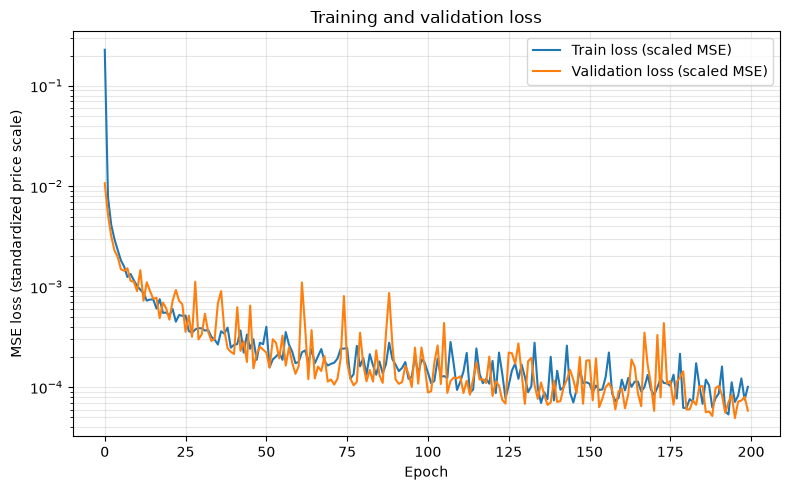

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(train_losses, label="Train loss (scaled MSE)")
ax.plot(val_losses, label="Validation loss (scaled MSE)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss (standardized price scale)")
ax.set_yscale("log")
ax.set_title("Training and validation loss")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(DATA_DIR / "ml_training_loss.png", dpi=150)
plt.show()


## 4. Evaluate on the held-out test set

Predictions are inverse-transformed back to actual price units before
computing error metrics, so results are directly comparable to the BSM/MC/
FFT errors reported in `01_bsm_mc_fft.ipynb`.

In [8]:
model.eval()
with torch.no_grad():
    test_pred_scaled = model(X_test_t).cpu().numpy()

test_pred_price = scaler_y.inverse_transform(test_pred_scaled).flatten()
test_true_price = y_test.flatten()

test_abs_error = np.abs(test_pred_price - test_true_price)

# Relative error is only meaningful once the true price is more than a few
# cents; deep out-of-the-money options can have a true price of a tiny
# fraction of a cent, which would make (abs_error / true_price) explode even
# though the absolute dollar error is small. Floor the denominator so those
# near-worthless options don't dominate the average, and report how many
# were affected for transparency.
REL_ERROR_FLOOR = 0.01
n_floored = int((test_true_price < REL_ERROR_FLOOR).sum())
test_rel_error = test_abs_error / np.maximum(test_true_price, REL_ERROR_FLOOR)

print(f"Test MAE : {test_abs_error.mean():.4f}")
print(f"Test RMSE: {np.sqrt(np.mean((test_pred_price - test_true_price) ** 2)):.4f}")
print(f"Test max abs error: {test_abs_error.max():.4f}")
print(f"Test mean relative error: {test_rel_error.mean():.4%} "
      f"(denominator floored at ${REL_ERROR_FLOOR:.2f}; "
      f"{n_floored}/{len(test_true_price)} options had true price below that floor)")


Test MAE : 0.1256
Test RMSE: 0.1700
Test max abs error: 2.4440
Test mean relative error: 38.0968% (denominator floored at $0.01; 63/7500 options had true price below that floor)


### Accuracy of actual (true FFT price) vs predicted (NN price)

For a regression problem like this, "accuracy" is not a single
classification-style percentage - instead we report:

- **R-squared (R^2)**: the fraction of variance in the true price that the
  model explains; 1.0 is a perfect fit, 0.0 is no better than always
  predicting the mean price.
- **Tolerance-band accuracy**: the percentage of test options whose
  predicted price falls within a given absolute dollar tolerance of the
  true price - a more intuitive "how often is it basically right" measure.

In [9]:
from sklearn.metrics import r2_score

r2 = r2_score(test_true_price, test_pred_price)
print(f"R-squared (actual vs predicted): {r2:.6f}")

for tolerance in (0.05, 0.10, 0.25, 0.50, 1.00):
    within = (test_abs_error <= tolerance).mean()
    print(f"Accuracy within ${tolerance:.2f}: {within:.2%}")


R-squared (actual vs predicted): 0.999935
Accuracy within $0.05: 27.09%
Accuracy within $0.10: 50.29%
Accuracy within $0.25: 88.76%
Accuracy within $0.50: 98.97%
Accuracy within $1.00: 99.95%


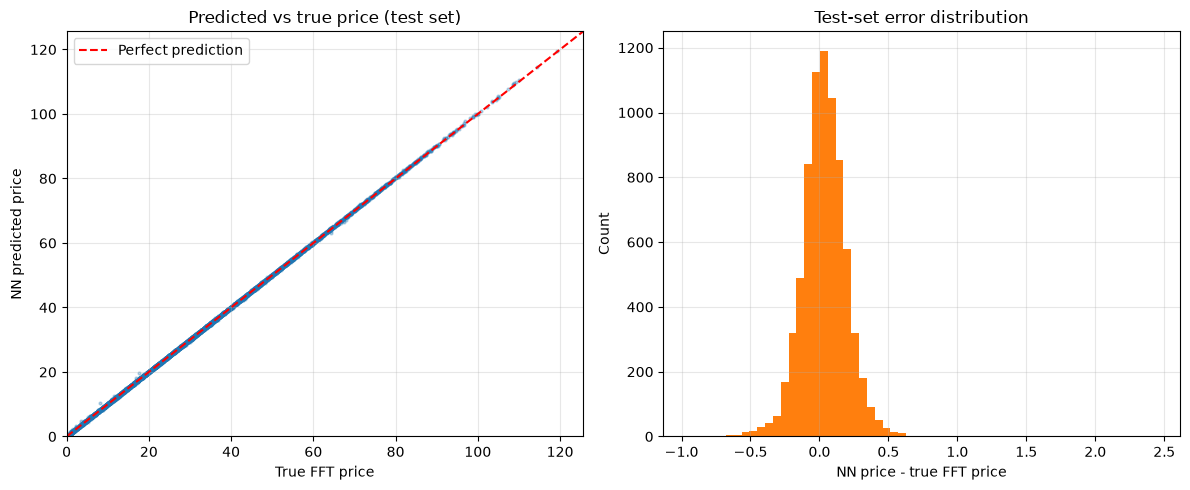

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

lims = [0, max(test_true_price.max(), test_pred_price.max()) * 1.05]
ax1.scatter(test_true_price, test_pred_price, s=4, alpha=0.3, color="tab:blue")
ax1.plot(lims, lims, "r--", linewidth=1.5, label="Perfect prediction")
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.set_xlabel("True FFT price")
ax1.set_ylabel("NN predicted price")
ax1.set_title("Predicted vs true price (test set)")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.hist(test_pred_price - test_true_price, bins=60, color="tab:orange")
ax2.set_xlabel("NN price - true FFT price")
ax2.set_ylabel("Count")
ax2.set_title("Test-set error distribution")
ax2.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(DATA_DIR / "ml_test_parity.png", dpi=150)
plt.show()


## 5. Apply the trained model to brand-new, unseen points

Sample a fresh batch of option parameter sets (different seed, so these
points were never used in training/validation/testing), price them with
FFT (and BSM, since it is exact under GBM and lets us sanity-check both FFT
and the NN at once), and compare against the NN's predictions.

In [11]:
N_NEW = 500
NEW_SEED = SEED + 999

new_options = make_dataset(N_NEW, NEW_SEED)
new_df = pd.DataFrame(new_options)
new_df["bsm_price"] = [bsm_call(**p) for p in new_options]
new_df["fft_price"] = [carr_madan_call(**p) for p in new_options]

X_new = new_df[FEATURE_NAMES].to_numpy(dtype=np.float32)
X_new_t = to_tensor(scaler_X.transform(X_new)).to(device)

model.eval()
with torch.no_grad():
    new_pred_scaled = model(X_new_t).cpu().numpy()
new_df["nn_price"] = scaler_y.inverse_transform(new_pred_scaled).flatten()

new_df["nn_abs_error_vs_fft"] = (new_df["nn_price"] - new_df["fft_price"]).abs()
new_df["nn_abs_error_vs_bsm"] = (new_df["nn_price"] - new_df["bsm_price"]).abs()

print(f"NN vs FFT on {N_NEW} brand-new points: mean abs error = {new_df['nn_abs_error_vs_fft'].mean():.4f}, "
      f"max abs error = {new_df['nn_abs_error_vs_fft'].max():.4f}")
print(f"NN vs BSM on {N_NEW} brand-new points: mean abs error = {new_df['nn_abs_error_vs_bsm'].mean():.4f}, "
      f"max abs error = {new_df['nn_abs_error_vs_bsm'].max():.4f}")

new_df.head()


NN vs FFT on 500 brand-new points: mean abs error = 0.1257, max abs error = 0.9411
NN vs BSM on 500 brand-new points: mean abs error = 0.1257, max abs error = 0.9412


,spot,strike,rate,sigma,tau,bsm_price,fft_price,nn_price,nn_abs_error_vs_fft,nn_abs_error_vs_bsm
0,142.300797,146.226632,0.034705,0.298349,0.105008,4.018882,4.018973,4.197340,0.178367,0.178458
1,137.102931,134.294229,0.094750,0.147616,2.218062,30.287861,30.287870,29.962591,0.325279,0.325270
2,123.471382,119.782556,0.084506,0.568387,2.302114,50.654188,50.654188,50.605377,0.048811,0.048811
3,176.431850,131.738423,0.087074,0.095432,1.236104,58.136684,58.136661,57.887302,0.249359,0.249381
4,71.564582,78.871311,-0.015894,0.398771,2.370192,13.765097,13.765103,13.803555,0.038451,0.038457


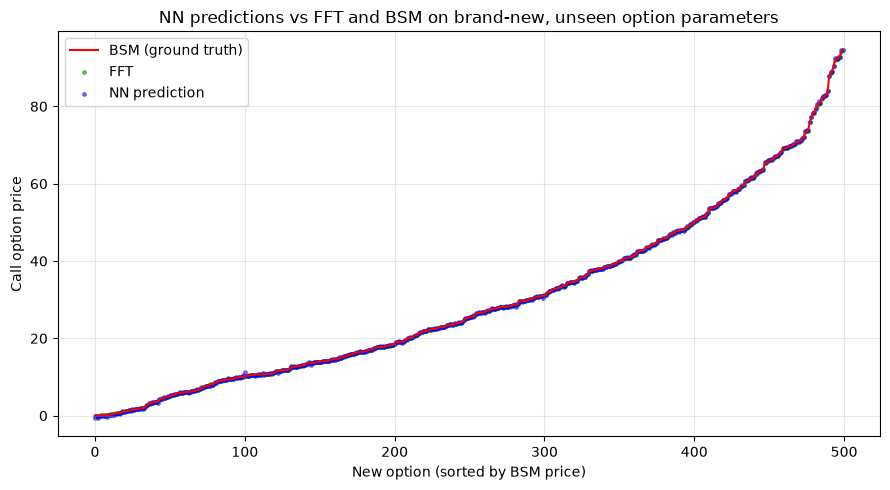

In [12]:
order = np.argsort(new_df["bsm_price"].to_numpy())
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(N_NEW), new_df["bsm_price"].to_numpy()[order], color="red",
        label="BSM (ground truth)", linewidth=1.5)
ax.scatter(np.arange(N_NEW), new_df["fft_price"].to_numpy()[order], s=6, color="green",
           alpha=0.5, label="FFT")
ax.scatter(np.arange(N_NEW), new_df["nn_price"].to_numpy()[order], s=6, color="blue",
           alpha=0.5, label="NN prediction")
ax.set_xlabel("New option (sorted by BSM price)")
ax.set_ylabel("Call option price")
ax.set_title("NN predictions vs FFT and BSM on brand-new, unseen option parameters")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(DATA_DIR / "ml_new_points.png", dpi=150)
plt.show()


## 6. Save artifacts for the final comparison notebook

Save the trained model weights, the input/output scalers (needed to run
the model on new raw parameter values later), and a results table with
per-option NN vs FFT timing, so `03_comparison.ipynb` can reuse the trained
model without retraining.

In [13]:
torch.save(model.state_dict(), MODELS_DIR / "option_pricer_mlp.pt")
joblib.dump(scaler_X, MODELS_DIR / "scaler_X.joblib")
joblib.dump(scaler_y, MODELS_DIR / "scaler_y.joblib")

# Timing comparison: FFT (one option at a time) vs NN (single batched forward pass)
# on the same new_df points, as a first look at the per-query cost difference explored
# further in 03_comparison.ipynb.
t0 = time.perf_counter()
_ = [carr_madan_call(**p) for p in new_options]
fft_batch_seconds = time.perf_counter() - t0

model.eval()
with torch.no_grad():
    t0 = time.perf_counter()
    _ = model(X_new_t).cpu().numpy()
    nn_batch_seconds = time.perf_counter() - t0

print(f"FFT: {fft_batch_seconds * 1e6 / N_NEW:.1f} us/option (looped, one option at a time)")
print(f"NN : {nn_batch_seconds * 1e6 / N_NEW:.1f} us/option (single batched forward pass, {N_NEW} options)")
print(f"Speedup: {fft_batch_seconds / nn_batch_seconds:.1f}x")

new_df.to_csv(DATA_DIR / "ml_fft_results.csv", index=False)
print("Saved model, scalers, and ml_fft_results.csv")


FFT: 775.9 us/option (looped, one option at a time)
NN : 1.0 us/option (single batched forward pass, 500 options)
Speedup: 802.5x
Saved model, scalers, and ml_fft_results.csv


**Takeaways**

- The FFT-generated `(x, y)` dataset (`data/fft_training_dataset.csv`,
  `N_TOTAL` rows) lets the neural network learn a direct mapping from
  option parameters to price, without evaluating the characteristic
  function at inference time.
- Test-set and brand-new-point errors should both be small relative to the
  option price scale, showing the network generalizes rather than
  memorizing the training set.
- Once trained, a single batched forward pass prices many options at once,
  which is expected to be substantially faster per option than looping
  FFT evaluations - quantified further, alongside BSM and MC, in
  `03_comparison.ipynb`.

## 7. Gaussian Process Regression (GPR): reproducing De Spiegeleer et al. (2018)

[`material/Machine learning for quantitative finance fast derivative
pricing hedging and fitting.pdf`](material/Machine%20learning%20for%20quantitative%20finance%20%20fast%20derivative%20pricing%20%20hedging%20and%20fitting.pdf)
(De Spiegeleer, Madan, Reyners & Schoutens, *Quantitative Finance*, 2018)
is the paper this project's FFT-dataset-to-ML idea is based on. Its actual
ML model is **Gaussian Process Regression (GPR)**, not Gradient Boosting -
the paper never mentions gradient boosting. This section implements GPR on
our Black-Scholes/GBM dataset and reports the same metrics the paper
reports, so it can be compared against the FNN above.

**The paper's metric definitions** (note: the paper's naming is the
*reverse* of the usual convention - we follow the paper's names here, not
the common ML meaning of "MAE"):

- `MAE = max(|FFT price - model price|)` - the **maximum** absolute error.
- `AAE = mean(|FFT price - model price|)` - the **average** absolute error
  (what is usually called MAE elsewhere).
- Both are reported **in-sample** (on the training set) and
  **out-of-sample** (on a held-out test set), plus a **speed-up** factor
  (FFT compute time / model predict time on the same batch).
- The paper trains separate GPR models on training sets of size 5,000 /
  10,000 / 20,000.

**Caveats / deliberate deviations from the paper, noted explicitly:**

1. The paper prices options under the Variance Gamma (VG) and Heston
   models; we are still on plain Black-Scholes/GBM (per the earlier scope
   decision - Heston is planned as later work). So the *absolute* error
   and speed-up numbers below are **not expected to numerically match**
   the paper's Table 2 - the comparison here is about whether the same
   *qualitative* pattern holds (error shrinks as training size grows,
   speed-ups of multiple orders of magnitude), not an exact replication.
2. Exact GPR has `O(n^3)` fit cost in the number of training points. The
   paper's largest size (20,000) would take far too long to fit here, so
   we use smaller sizes (`GPR_TRAIN_SIZES` below). We also fit the kernel's
   hyperparameters (length scales, noise level) **once**, via gradient-based
   optimization on the smallest training size, and then reuse that fixed,
   genuinely-fitted kernel for the larger sizes - repeating the
   hyperparameter search at every size would multiply the already-cubic
   cost several times over.

In [14]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel


def paper_style_errors(true_price: np.ndarray, pred_price: np.ndarray) -> tuple[float, float]:
    """Returns (MAE, AAE) using the paper's definitions: MAE = max abs error,
    AAE = mean abs error (i.e. the usual definition of MAE elsewhere)."""
    abs_err = np.abs(true_price - pred_price)
    return float(abs_err.max()), float(abs_err.mean())


GPR_TRAIN_SIZES = [2000, 5000, 10000]
GPR_TEST_SIZE = 2000  # shared out-of-sample batch, reused for the FNN comparison below too

X_gpr_test = X_test[:GPR_TEST_SIZE]
y_gpr_test = y_test[:GPR_TEST_SIZE].flatten()

# FFT compute time on this exact shared out-of-sample batch, needed for the speed-up ratios.
fft_test_options = [dict(zip(FEATURE_NAMES, (float(v) for v in row))) for row in X_gpr_test]
t0 = time.perf_counter()
_ = [carr_madan_call(**p) for p in fft_test_options]
fft_test_seconds = time.perf_counter() - t0
print(f"FFT pricing of the shared {GPR_TEST_SIZE}-option out-of-sample batch took "
      f"{fft_test_seconds:.3f}s ({fft_test_seconds / GPR_TEST_SIZE * 1e6:.1f} us/option)")


FFT pricing of the shared 2000-option out-of-sample batch took 1.602s (801.1 us/option)


In [15]:
base_size = min(GPR_TRAIN_SIZES)
scaler_X_base = StandardScaler().fit(X_train[:base_size])
scaler_y_base = StandardScaler().fit(y_train[:base_size])
X_base_scaled = scaler_X_base.transform(X_train[:base_size])
y_base_scaled = scaler_y_base.transform(y_train[:base_size]).flatten()

init_kernel = (ConstantKernel(1.0, (1e-2, 1e2))
               * RBF(length_scale=np.ones(len(FEATURE_NAMES)), length_scale_bounds=(1e-2, 1e2))
               + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-6, 1e-1)))

print(f"Fitting GPR kernel hyperparameters once on {base_size} points...")
t0 = time.perf_counter()
gpr_base = GaussianProcessRegressor(kernel=init_kernel, random_state=SEED, n_restarts_optimizer=1)
gpr_base.fit(X_base_scaled, y_base_scaled)
print(f"Hyperparameter fit took {time.perf_counter() - t0:.1f}s")
print("Learned kernel:", gpr_base.kernel_)

fixed_kernel = gpr_base.kernel_


Fitting GPR kernel hyperparameters once on 2000 points...


Hyperparameter fit took 27.6s
Learned kernel: 2.58**2 * RBF(length_scale=[1.21, 1.15, 8.14, 1.86, 1.85]) + WhiteKernel(noise_level=1.9e-05)


In [16]:
gpr_rows = []
for n_train in GPR_TRAIN_SIZES:
    X_sub = X_train[:n_train]
    y_sub = y_train[:n_train].flatten()

    scaler_X_g = StandardScaler().fit(X_sub)
    scaler_y_g = StandardScaler().fit(y_sub.reshape(-1, 1))
    X_sub_scaled = scaler_X_g.transform(X_sub)
    y_sub_scaled = scaler_y_g.transform(y_sub.reshape(-1, 1)).flatten()

    gpr = GaussianProcessRegressor(kernel=fixed_kernel, optimizer=None)
    t0 = time.perf_counter()
    gpr.fit(X_sub_scaled, y_sub_scaled)
    fit_seconds = time.perf_counter() - t0

    pred_in_scaled = gpr.predict(X_sub_scaled)
    pred_in = scaler_y_g.inverse_transform(pred_in_scaled.reshape(-1, 1)).flatten()
    mae_in, aae_in = paper_style_errors(y_sub, pred_in)

    X_test_scaled_g = scaler_X_g.transform(X_gpr_test)
    t0 = time.perf_counter()
    pred_out_scaled = gpr.predict(X_test_scaled_g)
    predict_seconds = time.perf_counter() - t0
    pred_out = scaler_y_g.inverse_transform(pred_out_scaled.reshape(-1, 1)).flatten()
    mae_out, aae_out = paper_style_errors(y_gpr_test, pred_out)

    gpr_rows.append({
        "model": "GPR", "train_size": n_train,
        "mae_in_sample": mae_in, "aae_in_sample": aae_in,
        "mae_out_sample": mae_out, "aae_out_sample": aae_out,
        "fit_seconds": fit_seconds, "predict_seconds_batch": predict_seconds,
        "speed_up_vs_fft": fft_test_seconds / predict_seconds,
    })
    print(f"n_train={n_train:6d}  fit={fit_seconds:6.1f}s  "
          f"in-sample MAE(max)={mae_in:.4f} AAE(mean)={aae_in:.4f}  "
          f"out-of-sample MAE(max)={mae_out:.4f} AAE(mean)={aae_out:.4f}  "
          f"speed-up={gpr_rows[-1]['speed_up_vs_fft']:.1f}x")


n_train=  2000  fit=   0.1s  in-sample MAE(max)=0.4947 AAE(mean)=0.0420  out-of-sample MAE(max)=3.3675 AAE(mean)=0.1430  speed-up=50.0x


n_train=  5000  fit=   1.3s  in-sample MAE(max)=1.0669 AAE(mean)=0.0530  out-of-sample MAE(max)=1.7011 AAE(mean)=0.0899  speed-up=18.6x


n_train= 10000  fit=   8.9s  in-sample MAE(max)=1.0147 AAE(mean)=0.0556  out-of-sample MAE(max)=1.4004 AAE(mean)=0.0720  speed-up=6.9x


### FNN metrics in the same paper-style terms, for direct comparison

Compute the FNN's in-sample error (on its full 35,000-row training set)
and out-of-sample error on **the same shared `GPR_TEST_SIZE`-option batch**
used for GPR above, so the two models are compared on identical data
points.

In [17]:
model.eval()
with torch.no_grad():
    fnn_in_pred_scaled = model(X_train_t).cpu().numpy()
    X_gpr_test_t = to_tensor(scaler_X.transform(X_gpr_test)).to(device)
    t0 = time.perf_counter()
    fnn_out_pred_scaled = model(X_gpr_test_t).cpu().numpy()
    fnn_predict_seconds = time.perf_counter() - t0

fnn_in_pred = scaler_y.inverse_transform(fnn_in_pred_scaled).flatten()
fnn_out_pred = scaler_y.inverse_transform(fnn_out_pred_scaled).flatten()

mae_in_fnn, aae_in_fnn = paper_style_errors(y_train.flatten(), fnn_in_pred)
mae_out_fnn, aae_out_fnn = paper_style_errors(y_gpr_test, fnn_out_pred)
fnn_speed_up = fft_test_seconds / fnn_predict_seconds

print(f"FNN (train_size={len(X_train):,})  "
      f"in-sample MAE(max)={mae_in_fnn:.4f} AAE(mean)={aae_in_fnn:.4f}  "
      f"out-of-sample MAE(max)={mae_out_fnn:.4f} AAE(mean)={aae_out_fnn:.4f}  "
      f"speed-up={fnn_speed_up:.1f}x")


FNN (train_size=35,000)  in-sample MAE(max)=1.4130 AAE(mean)=0.1120  out-of-sample MAE(max)=0.9613 AAE(mean)=0.1239  speed-up=187.3x


In [18]:
comparison_rows = list(gpr_rows)
comparison_rows.append({
    "model": "FNN", "train_size": len(X_train),
    "mae_in_sample": mae_in_fnn, "aae_in_sample": aae_in_fnn,
    "mae_out_sample": mae_out_fnn, "aae_out_sample": aae_out_fnn,
    "fit_seconds": float("nan"),
    "predict_seconds_batch": fnn_predict_seconds,
    "speed_up_vs_fft": fnn_speed_up,
})

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(DATA_DIR / "gpr_fnn_paper_metrics.csv", index=False)
comparison_df


,model,train_size,mae_in_sample,aae_in_sample,mae_out_sample,aae_out_sample,fit_seconds,predict_seconds_batch,speed_up_vs_fft
0,GPR,2000,0.494747,0.041967,3.367491,0.143028,0.105118,0.032051,49.986564
1,GPR,5000,1.066940,0.053019,1.701069,0.089861,1.329899,0.086062,18.616062
2,GPR,10000,1.014680,0.055645,1.400357,0.072034,8.918530,0.233246,6.868874
3,FNN,35000,1.413005,0.112015,0.961296,0.123935,NaN,0.008554,187.306326


### Does the pattern match the paper?

The paper's Table 2 shows, for both VG and Heston: (a) out-of-sample AAE
decreasing as the training set grows, (b) speed-ups ranging from about 7x
to 40x for GPR. We check whether our Black-Scholes run shows the same
*qualitative* pattern (absolute numbers will differ, per the caveats
above).

In [19]:
print("=== Checking our results against the paper's reported pattern ===")
print("(Table 2 of De Spiegeleer et al., 2018 - VG and Heston, not Black-Scholes, so absolute")
print("error/speed-up values are not expected to match numerically.)\n")

gpr_only = comparison_df[comparison_df["model"] == "GPR"].sort_values("train_size")
mono_out = bool(gpr_only["aae_out_sample"].is_monotonic_decreasing)
mono_in = bool(gpr_only["aae_in_sample"].is_monotonic_decreasing)
print(f"GPR out-of-sample AAE decreases monotonically as training size grows "
      f"({list(gpr_only['train_size'])}): {mono_out}")
print(f"GPR in-sample AAE decreases monotonically as training size grows: {mono_in}")

best_gpr = gpr_only.iloc[-1]
fnn_row = comparison_df[comparison_df['model'] == 'FNN'].iloc[0]
print(f"\nBest GPR (n_train={best_gpr['train_size']:.0f}): "
      f"out-of-sample AAE={best_gpr['aae_out_sample']:.4f}, "
      f"speed-up={best_gpr['speed_up_vs_fft']:.1f}x "
      f"(paper's GPR speed-ups range ~7x-40x)")
print(f"FNN (n_train={fnn_row['train_size']:.0f}): "
      f"out-of-sample AAE={fnn_row['aae_out_sample']:.4f}, "
      f"speed-up={fnn_row['speed_up_vs_fft']:.1f}x")

better = "FNN" if fnn_row["aae_out_sample"] < best_gpr["aae_out_sample"] else "GPR"
print(f"\nOn this Black-Scholes dataset, {better} achieves the lower out-of-sample AAE.")


=== Checking our results against the paper's reported pattern ===
(Table 2 of De Spiegeleer et al., 2018 - VG and Heston, not Black-Scholes, so absolute
error/speed-up values are not expected to match numerically.)

GPR out-of-sample AAE decreases monotonically as training size grows ([2000, 5000, 10000]): True
GPR in-sample AAE decreases monotonically as training size grows: False

Best GPR (n_train=10000): out-of-sample AAE=0.0720, speed-up=6.9x (paper's GPR speed-ups range ~7x-40x)
FNN (n_train=35000): out-of-sample AAE=0.1239, speed-up=187.3x

On this Black-Scholes dataset, GPR achieves the lower out-of-sample AAE.


**Takeaways (GPR section)**

- The paper's actual ML model is Gaussian Process Regression, not gradient
  boosting - implemented here as such, with the paper's own `MAE`
  (maximum error) / `AAE` (average error) metric definitions.
- Because our dataset is Black-Scholes/GBM rather than the paper's VG/
  Heston setup, exact error and speed-up magnitudes are not expected to
  match the paper's published numbers - what we check instead is whether
  the *shape* of the result (error shrinking with more training data,
  large speed-ups over FFT) holds here too.
- `data/gpr_fnn_paper_metrics.csv` carries both models' paper-style metrics
  forward for `03_comparison.ipynb`.
- Next step (separately planned): repeat this with a Heston-model FFT
  pricer, which would let the comparison target the paper's own published
  numbers directly.